## Ensemble Models Notebook
This notebook trains and evaluates ensemble models using the project's modular Python scripts:
- `config/config.py` for run configuration
- `data/data_loader.py` for loading and splitting data
- `preprocessing/` modules for cleaning, encoding, and scaling
- `balancing/balancer.py` for handling class imbalance
- `training/trainer.py` for training loops and evaluation
- `utils/metrics.py` for reporting and metrics

The preprocessing pipeline is **identical** to Notebook 2 (Logistic Regression).
Only the models being trained differ: Random Forest, XGBoost, and Balanced Random Forest.

In [27]:
import sys
from pathlib import Path

# Add project root (DE_project_S5) to sys.path
PROJECT_ROOT = Path().resolve().parent
sys.path.append(str(PROJECT_ROOT))

print("Project root added:", PROJECT_ROOT)

import pandas as pd
import numpy as np

Project root added: maintain-ai/backend


In [28]:
# Data
from maintenance_ml.data.data_loader import load_data

# Pipeline
from maintenance_ml.pipeline.build_pipeline import run_pipeline

# Training
from maintenance_ml.training.trainer import train_model, evaluate_model

# Confusion Matrix
from maintenance_ml.utils.metrices import plot_confusion_matrix

# Model I/O
from maintenance_ml.utils.model_io import save_model

# Ensemble models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.ensemble import BalancedRandomForestClassifier

In [29]:
# Load data
DATA_PATH = PROJECT_ROOT / "data" / "scaled_dataset.csv"

df = load_data(DATA_PATH)
df.columns = df.columns.str.replace(r"[\[\]]", "", regex=True)
df.head()

,UDI,Product ID,Type,Air temperature K,Process temperature K,Rotational speed rpm,Torque Nm,Vibration Levels,Operational Hours,Failure Type
0,292,L47471,L,298.0,308.3,1473,42.6,39.0,91.58,No Failure
1,70,L47249,L,298.9,309.0,1410,65.7,42.0,47.00,Failure
2,70,L47249,L,298.9,309.0,1410,65.7,42.0,47.00,Failure
3,361,M15220,M,297.5,308.3,1521,38.2,35.0,116.05,Failure
4,27,L47206,L,299.1,309.5,1512,39.0,36.0,24.48,No Failure


## Data Preprocessing Pipeline
Run the complete preprocessing pipeline to prepare data for model training:
- Clean and handle missing values
- Encode categorical features
- Scale numerical features
- Balance class distribution using SMOTE
- Split into train/test sets

In [30]:
X_train, X_test, y_train, y_test = run_pipeline(df)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Encoding columns: ['Type']
Train shape: (530, 9)
Test shape: (73, 9)


## Random Forest Classifier
Train and evaluate a Random Forest classifier for failure prediction.

In [31]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model = train_model(model, X_train, y_train)

results = evaluate_model(model, X_test, y_test)
print(results["report"])

              precision    recall  f1-score   support

           0       0.95      0.95      0.95        66
           1       0.57      0.57      0.57         7

    accuracy                           0.92        73
   macro avg       0.76      0.76      0.76        73
weighted avg       0.92      0.92      0.92        73



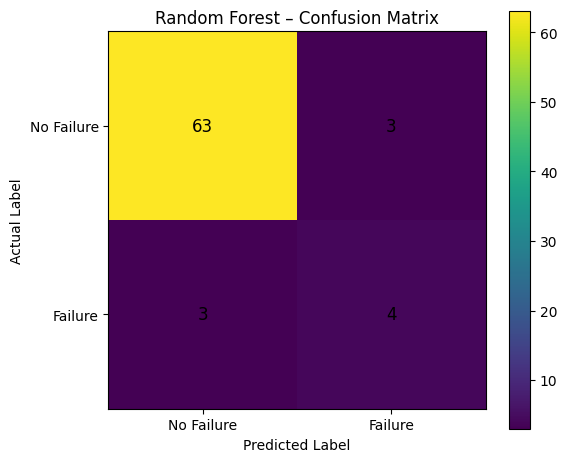

In [32]:
cm = results["confusion_matrix"]

plot_confusion_matrix(
    cm,
    title="Random Forest – Confusion Matrix"
)

In [33]:
model_path = save_model(
    model,
    model_name="random_forest_failure_prediction"
)
print("Model saved at:", model_path)

Model saved at: artifacts\random_forest_failure_prediction.joblib
Model saved at: artifacts\random_forest_failure_prediction.joblib


## XGBoost Classifier
Train and evaluate an XGBoost classifier for failure prediction.

In [34]:
model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=13,
    eval_metric="logloss",
    random_state=42
)
model = train_model(model, X_train, y_train)

results = evaluate_model(model, X_test, y_test)
print(results["report"])

              precision    recall  f1-score   support

           0       0.95      0.83      0.89        66
           1       0.27      0.57      0.36         7

    accuracy                           0.81        73
   macro avg       0.61      0.70      0.63        73
weighted avg       0.88      0.81      0.84        73



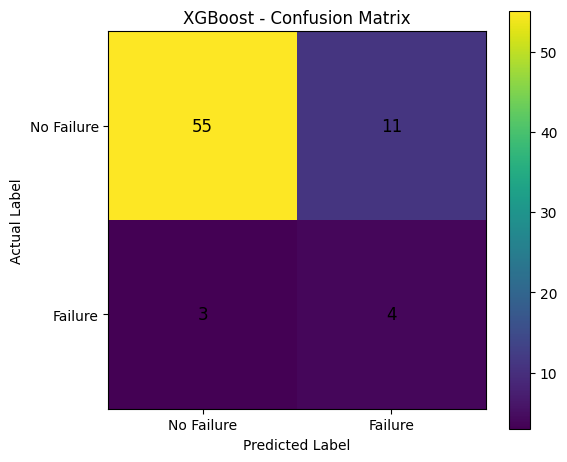

In [35]:
cm = results["confusion_matrix"]

plot_confusion_matrix(
    cm,
    title="XGBoost - Confusion Matrix"
)

In [36]:
model_path = save_model(
    model,
    model_name="xgboost_failure_prediction"
)
print("Model saved at:", model_path)

Model saved at: artifacts\xgboost_failure_prediction.joblib
Model saved at: artifacts\xgboost_failure_prediction.joblib


## Balanced Random Forest Classifier
Train and evaluate a Balanced Random Forest classifier for failure prediction.

In [37]:
model = BalancedRandomForestClassifier(
    n_estimators=200,
    random_state=42
)
model = train_model(model, X_train, y_train)

results = evaluate_model(model, X_test, y_test)
print(results["report"])

              precision    recall  f1-score   support

           0       0.96      0.97      0.96        66
           1       0.67      0.57      0.62         7

    accuracy                           0.93        73
   macro avg       0.81      0.77      0.79        73
weighted avg       0.93      0.93      0.93        73



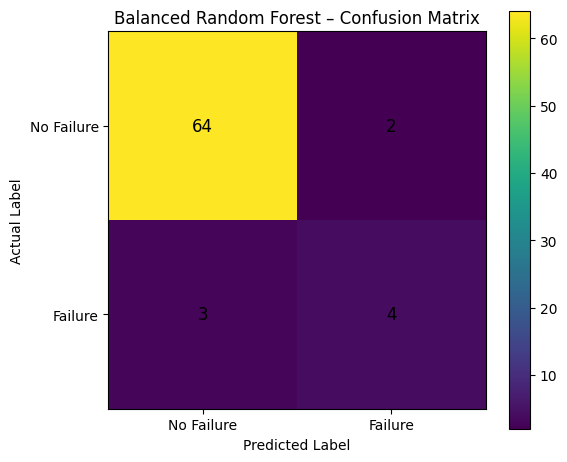

In [38]:
cm = results["confusion_matrix"]

plot_confusion_matrix(
    cm,
    title="Balanced Random Forest – Confusion Matrix"
)

In [39]:
model_path = save_model(
    model,
    model_name="balanced_random_forest_failure_prediction"
)
print("Model saved at:", model_path)

Model saved at: artifacts\balanced_random_forest_failure_prediction.joblib
Model saved at: artifacts\balanced_random_forest_failure_prediction.joblib


## Fine tuning the balanced random forest
Grid search cv

In [40]:
from sklearn.model_selection import GridSearchCV

model = BalancedRandomForestClassifier(
    random_state=42
)

In [41]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

In [42]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [43]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",BalancedRando...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidat

In [44]:
print("Best Parameters:")
print(grid_search.best_params_)
best_model = grid_search.best_estimator_

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}


              precision    recall  f1-score   support

           0       0.95      0.95      0.95        66
           1       0.57      0.57      0.57         7

    accuracy                           0.92        73
   macro avg       0.76      0.76      0.76        73
weighted avg       0.92      0.92      0.92        73



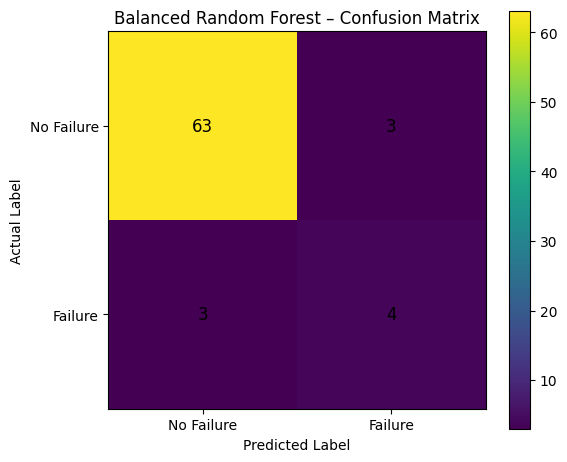

In [45]:
results = evaluate_model(best_model, X_test, y_test)
print(results["report"])

cm = results["confusion_matrix"]

plot_confusion_matrix(
    cm,
    title="Balanced Random Forest – Confusion Matrix"
)

In [46]:
model_path = save_model(
    best_model,
    model_name="fine_tuned_balanced_random_forest_failure_prediction"
)
print("Model saved at:", model_path)

Model saved at: artifacts\fine_tuned_balanced_random_forest_failure_prediction.joblib
Model saved at: artifacts\fine_tuned_balanced_random_forest_failure_prediction.joblib
